# Bike-Sharing Demand Investigation
## How do time, season, weather, and environment influence hourly demand?

**Research question:** How do time of day, season, weather, and other environmental
factors influence hourly bike-sharing demand, and can we build a model that reliably
predicts it?

**Dataset:** UCI Bike Sharing Dataset (Fanaee-T & Gama, 2013) — `hour.csv`  
**Target variable:** `cnt` — total hourly bike rentals (casual + registered)  
**Period covered:** 2011–2012, Washington D.C. Capital Bikeshare system

---

### How to run this notebook

This notebook is designed to execute **top to bottom** in Google Colab or any
Jupyter-compatible environment.

**Dataset (Section 2):** This notebook uses the canonical `hour.csv` from the
project repository (`data/raw/hour.csv`).

- **Local execution** (from the project root): the dataset is loaded automatically
  from `data/raw/hour.csv`. No download is needed.
- **Google Colab**: when the cell detects it is running in Colab, it prompts you
  to upload `hour.csv` from your local project clone
  (`data/raw/hour.csv`). Do **not** upload a different copy — the SHA-256
  checksum is verified to ensure dataset integrity. The checksum is computed
  after normalizing CRLF line endings to LF, so it does not depend on git
  line-ending settings.

> **GPU is not required.** All models use CPU-based scikit-learn.

---
## Section 1 — Environment Setup

Install and import all required libraries. In Google Colab, most of these are
pre-installed; this cell ensures exact versions are available.

In [1]:
# Install required libraries (safe to run in Colab or locally)
# !pip install -q scikit-learn pandas numpy matplotlib seaborn joblib

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

%matplotlib inline
print('Libraries loaded successfully.')

Libraries loaded successfully.


In [3]:
# ---------------------------------------------------------------------------
# Dataset Acquisition
# ---------------------------------------------------------------------------
# This notebook uses the canonical dataset from the project repository.
#
# LOCAL EXECUTION (from project root):
#   data/raw/hour.csv is loaded automatically — no download needed.
#
# GOOGLE COLAB EXECUTION:
#   The Colab runtime does not have access to your local project directory.
#   When this cell detects Colab and the file is not present, it prompts you
#   to upload hour.csv from your local copy of the project:
#     1. Run this cell.
#     2. Click 'Choose Files' in the upload widget.
#     3. Navigate to data/raw/hour.csv in your local project clone.
#     4. The cell verifies the SHA-256 checksum and loads the data.
#
# IMPORTANT: Do NOT use a different source file. Only the canonical
# data/raw/hour.csv produces the expected checksum.
# ---------------------------------------------------------------------------

import hashlib
import io
import os
from pathlib import Path

# SHA-256 checksum of the canonical data/raw/hour.csv.
# Used to verify that the file matches the project dataset exactly.
EXPECTED_SHA256 = 'b03a2d02e8c10f435c43c7f0b358b7e34a003afea53dbc37f0183f2763295133'
EXPECTED_ROWS = 17379
EXPECTED_COLS = 17

REQUIRED_COLUMNS = [
    'instant', 'dteday', 'season', 'yr', 'mnth', 'hr',
    'holiday', 'weekday', 'workingday', 'weathersit',
    'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt',
]


def _verify_csv_bytes(raw_bytes, label):
    'Verify SHA-256, shape, and schema; return the DataFrame.'
    # Hash is computed after CRLF->LF normalization so the check is independent of git line-ending settings; any content change still fails.
    normalized = raw_bytes.replace(b'\r\n', b'\n')
    digest = hashlib.sha256(normalized).hexdigest()
    if digest != EXPECTED_SHA256:
        raise ValueError(
            f'{label}: SHA-256 mismatch.\n'
            f'  Expected: {EXPECTED_SHA256}\n'
            f'  Got:      {digest}\n'
            'Ensure you are uploading data/raw/hour.csv from the project repository.'
        )
    df = pd.read_csv(io.BytesIO(raw_bytes))
    if df.shape != (EXPECTED_ROWS, EXPECTED_COLS):
        raise ValueError(
            f'{label}: unexpected shape {df.shape}; '
            f'expected ({EXPECTED_ROWS}, {EXPECTED_COLS}).'
        )
    missing = [c for c in REQUIRED_COLUMNS if c not in df.columns]
    if missing:
        raise ValueError(f'{label}: missing columns: {missing}')
    return df


def _is_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False


# Resolve the local path regardless of whether we are in repo root or notebooks/
_here = Path.cwd()
_local_candidates = [
    _here / 'data' / 'raw' / 'hour.csv',           # running from repo root
    _here.parent / 'data' / 'raw' / 'hour.csv',    # running from notebooks/
]
_local_path = next((p for p in _local_candidates if p.exists()), None)


if _local_path is not None:
    print(f'Loading local dataset from: {Path(os.path.relpath(_local_path)).as_posix()}')
    raw_bytes = _local_path.read_bytes()
    df = _verify_csv_bytes(raw_bytes, str(_local_path))
    print(f'Dataset verified: {df.shape[0]:,} rows × {df.shape[1]} columns')
    print(f'SHA-256: {EXPECTED_SHA256}')

elif _is_colab():
    print('Running in Google Colab — local project files are not available.')
    print()
    print('Please upload hour.csv from your local project clone:')
    print('  Local project path: data/raw/hour.csv')
    print()
    from google.colab import files
    uploaded = files.upload()          # prompts the file-picker widget
    if not uploaded:
        raise RuntimeError(
            'No file was uploaded. Re-run this cell and upload hour.csv.'
        )
    filename = list(uploaded.keys())[0]
    if not filename.endswith('hour.csv'):
        raise ValueError(
            f"Expected 'hour.csv', got '{filename}'. "
            'Please upload the correct file from data/raw/hour.csv.'
        )
    raw_bytes = uploaded[filename]
    df = _verify_csv_bytes(raw_bytes, f"uploaded '{filename}'")
    print(f'Dataset verified: {df.shape[0]:,} rows × {df.shape[1]} columns')
    print(f'SHA-256: {EXPECTED_SHA256}')

else:
    raise FileNotFoundError(
        'Cannot find data/raw/hour.csv.\n'
        'If running locally, ensure the working directory is the project root.\n'
        'If running in Google Colab, google.colab should be available automatically.\n'
        f'Searched: {[str(p) for p in _local_candidates]}'
    )


Loading local dataset from: data/raw/hour.csv
Dataset verified: 17,379 rows × 17 columns
SHA-256: b03a2d02e8c10f435c43c7f0b358b7e34a003afea53dbc37f0183f2763295133


In [4]:
print('Shape:', df.shape)
print()
print('First 3 rows:')
df.head(3)

Shape: (17379, 17)

First 3 rows:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32


---
## Section 2 — Data Exploration

Before modelling we inspect the dataset structure, verify data quality, and build
intuition about the target and predictors.

In [5]:
print('=== Dataset Overview ===')
print(f'Rows: {df.shape[0]:,}')
print(f'Columns: {df.shape[1]}')
print()
print('Column dtypes:')
print(df.dtypes)
print()
print('Descriptive statistics for numeric columns:')
df.describe().round(3)

=== Dataset Overview ===
Rows: 17,379
Columns: 17

Column dtypes:
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

Descriptive statistics for numeric columns:


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000
mean,8690.000,2.502,0.503,6.538,11.547,0.029,3.004,0.683,1.425,0.497,0.476,0.627,0.190,35.676,153.787,189.463
std,5017.029,1.107,0.500,3.439,6.914,0.167,2.006,0.465,0.639,0.193,0.172,0.193,0.122,49.305,151.357,181.388
min,1.000,1.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.020,0.000,0.000,0.000,0.000,0.000,1.000
25%,4345.500,2.000,0.000,4.000,6.000,0.000,1.000,0.000,1.000,0.340,0.333,0.480,0.104,4.000,34.000,40.000
50%,8690.000,3.000,1.000,7.000,12.000,0.000,3.000,1.000,1.000,0.500,0.485,0.630,0.194,17.000,115.000,142.000
75%,13034.500,3.000,1.000,10.000,18.000,0.000,5.000,1.000,2.000,0.660,0.621,0.780,0.254,48.000,220.000,281.000
max,17379.000,4.000,1.000,12.000,23.000,1.000,6.000,1.000,4.000,1.000,1.000,1.000,0.851,367.000,886.000,977.000


In [6]:
print('=== Missing Values and Duplicates ===')
missing = df.isnull().sum()
if missing.sum() > 0:
    print('Missing values per column:')
    print(missing[missing > 0])
else:
    print('Missing values: None  dataset is complete.')
print()
dup_count = df.duplicated().sum()
print(f'Duplicate rows: {dup_count}')

=== Missing Values and Duplicates ===
Missing values: None  dataset is complete.

Duplicate rows: 0


### Target Variable: `cnt`

`cnt` is the total number of bike rentals in a given hour. It equals `casual + registered`.
We exclude `casual` and `registered` as predictors because they would cause target leakage
--- together they sum exactly to `cnt`.

The distribution is right-skewed (skewness ≈ 1.28): most hours have moderate demand,
but a tail of peak hours inflates the mean above the median.

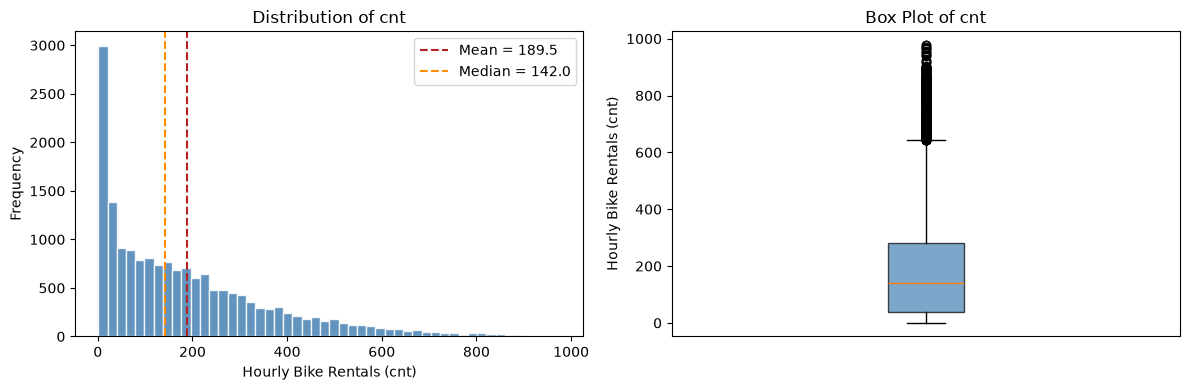

Mean:     189.5
Median:   142.0
Std Dev:  181.4
Min:      1
Max:      977
Skewness: 1.28


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram
axes[0].hist(df['cnt'], bins=50, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(df['cnt'].mean(), color='firebrick', linewidth=1.5, linestyle='--',
                label=f"Mean = {df['cnt'].mean():.1f}")
axes[0].axvline(df['cnt'].median(), color='darkorange', linewidth=1.5, linestyle='--',
                label=f"Median = {df['cnt'].median():.1f}")
axes[0].set_xlabel('Hourly Bike Rentals (cnt)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of cnt')
axes[0].legend()

# Box plot
axes[1].boxplot(df['cnt'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='steelblue', alpha=0.7))
axes[1].set_ylabel('Hourly Bike Rentals (cnt)')
axes[1].set_title('Box Plot of cnt')
axes[1].set_xticks([])

plt.tight_layout()
plt.show()

print(f"Mean:     {df['cnt'].mean():.1f}")
print(f"Median:   {df['cnt'].median():.1f}")
print(f"Std Dev:  {df['cnt'].std():.1f}")
print(f"Min:      {df['cnt'].min()}")
print(f"Max:      {df['cnt'].max()}")
print(f"Skewness: {df['cnt'].skew():.2f}")

### Hour-of-Day Pattern

The most striking feature is a **bimodal peak pattern** matching commuter behaviour:
- Morning peak at **08:00** (mean ≈ 359 rentals/hour)
- Evening peak at **17:00** (mean ≈ 462 rentals/hour — the daily maximum)
- Overnight minimum at **04:00** (mean ≈ 6 rentals/hour)

This non-linear, bimodal relationship is difficult for a linear model to capture
without feature engineering, but a Random Forest can learn it directly from the data.

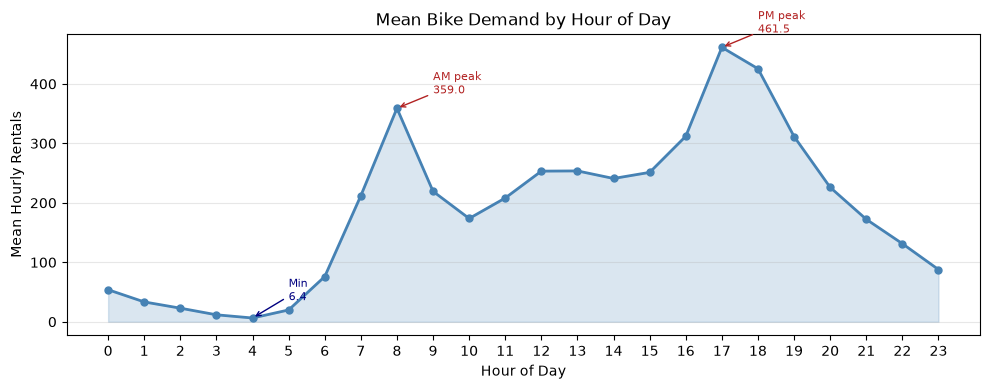

In [8]:
demand_by_hour = df.groupby('hr')['cnt'].mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(demand_by_hour.index, demand_by_hour.values,
        marker='o', linewidth=2, color='steelblue', markersize=5)
ax.fill_between(demand_by_hour.index, demand_by_hour.values,
                alpha=0.2, color='steelblue')

# Annotate peaks
ax.annotate(f'AM peak\n{demand_by_hour[8]:.1f}',
            xy=(8, demand_by_hour[8]),
            xytext=(9, demand_by_hour[8] + 25),
            fontsize=8, color='firebrick',
            arrowprops=dict(arrowstyle='->', color='firebrick', lw=1))
ax.annotate(f'PM peak\n{demand_by_hour[17]:.1f}',
            xy=(17, demand_by_hour[17]),
            xytext=(18, demand_by_hour[17] + 25),
            fontsize=8, color='firebrick',
            arrowprops=dict(arrowstyle='->', color='firebrick', lw=1))
ax.annotate(f'Min\n{demand_by_hour[4]:.1f}',
            xy=(4, demand_by_hour[4]),
            xytext=(5, demand_by_hour[4] + 30),
            fontsize=8, color='navy',
            arrowprops=dict(arrowstyle='->', color='navy', lw=1))

ax.set_xlabel('Hour of Day')
ax.set_ylabel('Mean Hourly Rentals')
ax.set_title('Mean Bike Demand by Hour of Day')
ax.set_xticks(range(0, 24))
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Seasonal Variation

Fall has the highest average demand (236.0); Spring has the lowest (111.1) —
a ratio of approximately **2.1:1**. This likely reflects temperature and daylight
effects on cycling.

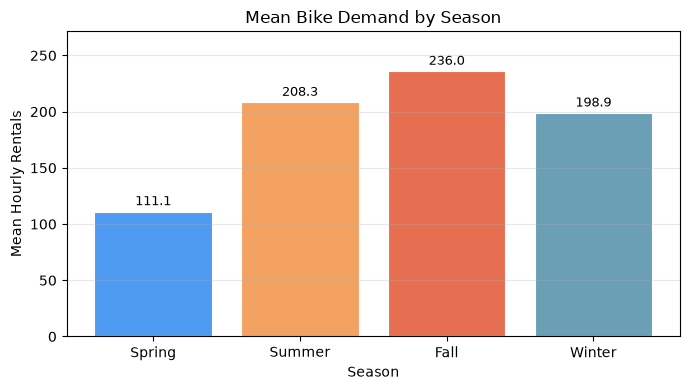

In [9]:
season_labels = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
demand_by_season = df.groupby('season')['cnt'].mean()

fig, ax = plt.subplots(figsize=(7, 4))
colors = ['#4e9af1', '#f4a261', '#e76f51', '#6a9fb5']
bars = ax.bar(
    [season_labels[s] for s in demand_by_season.index],
    demand_by_season.values,
    color=colors,
    edgecolor='white',
    linewidth=0.8
)

for bar, val in zip(bars, demand_by_season.values):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 3,
            f'{val:.1f}', ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Season')
ax.set_ylabel('Mean Hourly Rentals')
ax.set_title('Mean Bike Demand by Season')
ax.set_ylim(0, demand_by_season.max() * 1.15)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Weather Impact

Demand drops **monotonically** as conditions worsen:

| Code | Conditions | Mean cnt |
|------|-----------|----------|
| 1 | Clear / Few Clouds | 204.9 |
| 2 | Mist / Cloudy | 175.2 |
| 3 | Light Rain or Snow | 111.6 |
| 4 | Heavy Rain / Ice / Thunderstorm | 74.3 |

Note: Category 4 has only **3 observations** in the dataset —
its mean should be treated with caution.

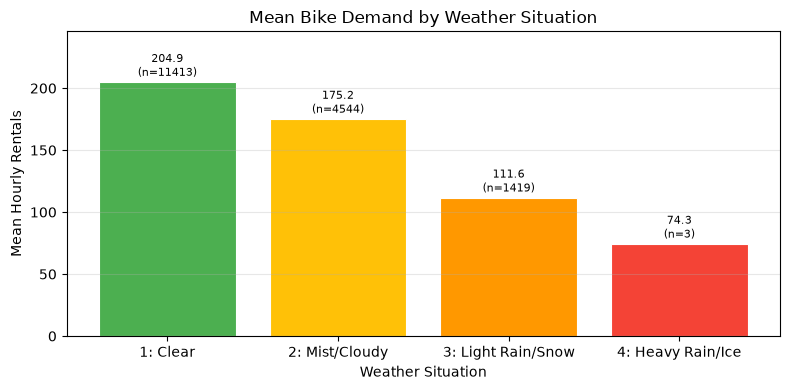

In [10]:
weather_labels = {
    1: '1: Clear',
    2: '2: Mist/Cloudy',
    3: '3: Light Rain/Snow',
    4: '4: Heavy Rain/Ice'
}
demand_by_weather = df.groupby('weathersit')['cnt'].mean()
obs_by_weather = df.groupby('weathersit')['cnt'].count()

fig, ax = plt.subplots(figsize=(8, 4))
palette = ['#4CAF50', '#FFC107', '#FF9800', '#F44336']
bars = ax.bar(
    [weather_labels[w] for w in demand_by_weather.index],
    demand_by_weather.values,
    color=palette[:len(demand_by_weather)],
    edgecolor='white',
    linewidth=0.8
)

for bar, val, n in zip(bars, demand_by_weather.values, obs_by_weather.values):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 2,
            f'{val:.1f}\n(n={n})',
            ha='center', va='bottom', fontsize=8)

ax.set_xlabel('Weather Situation')
ax.set_ylabel('Mean Hourly Rentals')
ax.set_title('Mean Bike Demand by Weather Situation')
ax.set_ylim(0, demand_by_weather.max() * 1.2)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Correlation Analysis

Pearson correlations between each predictor and `cnt` reveal:
- **`temp` (+0.405)** and **`atemp` (+0.401)** are the strongest linear correlates
  — warmer weather brings more riders.
- **`hr` (+0.394)** captures the time-of-day effect, though the linear coefficient
  understates the bimodal pattern.
- **`hum` (−0.323)** — higher humidity suppresses demand.
- **`weathersit` (−0.142)** — worse weather reduces demand.

**Important:** Correlations describe statistical associations, not causal mechanisms.

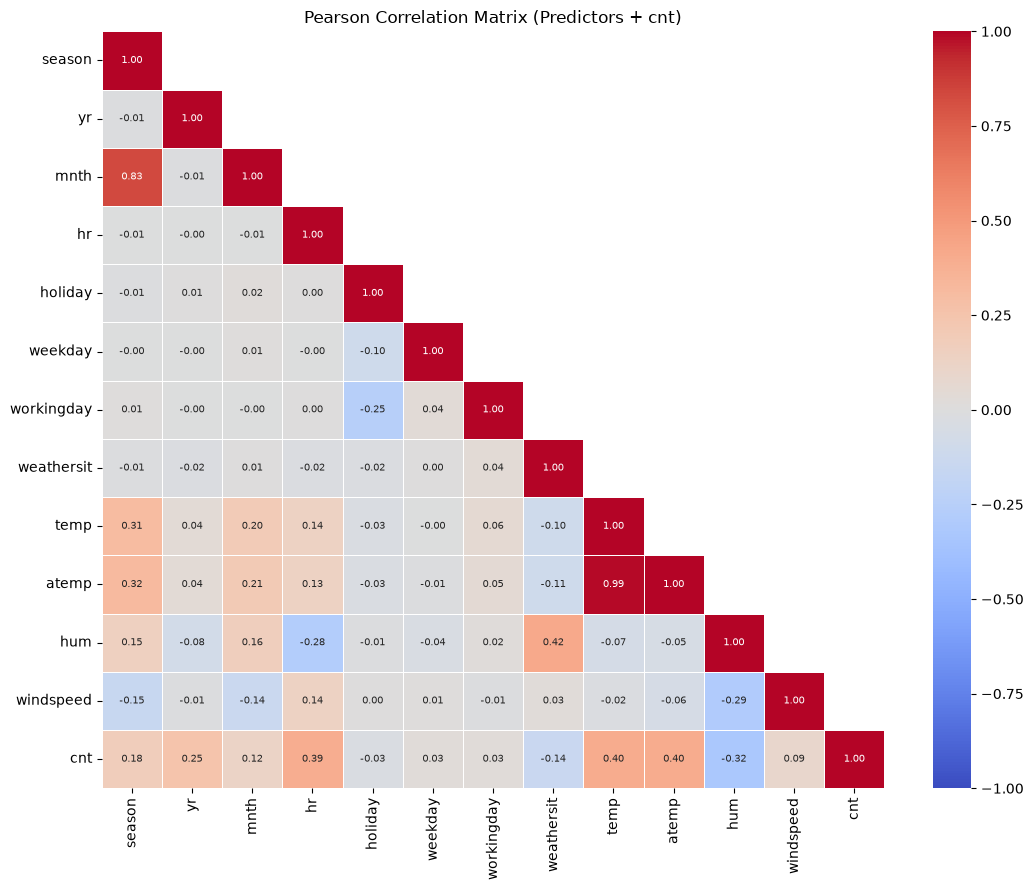


Correlation with target (cnt):
temp          0.405
atemp         0.401
hr            0.394
yr            0.250
season        0.178
mnth          0.121
windspeed     0.093
workingday    0.030
weekday       0.027
holiday      -0.031
weathersit   -0.142
hum          -0.323
Name: cnt, dtype: float64


In [11]:
FEATURE_COLS = [
    'season', 'yr', 'mnth', 'hr',
    'holiday', 'weekday', 'workingday', 'weathersit',
    'temp', 'atemp', 'hum', 'windspeed'
]
TARGET_COL = 'cnt'

corr_cols = FEATURE_COLS + [TARGET_COL]
corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.zeros_like(corr_matrix, dtype=bool)
mask[np.triu_indices_from(mask, k=1)] = True  # show lower triangle

sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f',
    cmap='coolwarm', center=0, vmin=-1, vmax=1,
    linewidths=0.5, annot_kws={'size': 7}, ax=ax
)
ax.set_title('Pearson Correlation Matrix (Predictors + cnt)')
plt.tight_layout()
plt.show()

print('\nCorrelation with target (cnt):')
print(corr_matrix[TARGET_COL].drop(TARGET_COL).sort_values(ascending=False).round(3))

---
## Section 3 — Feature Selection and Train/Test Split

### Excluded columns

| Column | Reason for exclusion |
|--------|----------------------|
| `cnt` | Target variable — not a predictor |
| `casual` | Directly contributes to `cnt` → **target leakage** |
| `registered` | Directly contributes to `cnt` → **target leakage** |
| `instant` | Row identifier — carries no predictive information |
| `dteday` | String date — calendar information already encoded in `yr`, `mnth`, `hr` |

### Feature columns used (12 predictors)

`season`, `yr`, `mnth`, `hr`, `holiday`, `weekday`, `workingday`,
`weathersit`, `temp`, `atemp`, `hum`, `windspeed`

### Chronological split

The dataset is ordered by `instant` (row number = chronological order).
We use an **80/20 chronological split** — no shuffling — so the model never
trains on data from the future relative to the test period. This is essential
for time-series-structured data to avoid information leakage.

In [12]:
FEATURE_COLS = [
    'season', 'yr', 'mnth', 'hr',
    'holiday', 'weekday', 'workingday', 'weathersit',
    'temp', 'atemp', 'hum', 'windspeed'
]
TARGET_COL = 'cnt'

# Sort by instant to ensure chronological order
df_sorted = df.sort_values('instant').reset_index(drop=True)

# 80 / 20 chronological split
split_idx = int(len(df_sorted) * 0.80)
df_train = df_sorted.iloc[:split_idx]
df_test  = df_sorted.iloc[split_idx:]

X_train = df_train[FEATURE_COLS]
y_train = df_train[TARGET_COL]
X_test  = df_test[FEATURE_COLS]
y_test  = df_test[TARGET_COL]

print(f'Total rows:  {len(df_sorted):,}')
print(f'Train rows:  {len(df_train):,}  ({split_idx / len(df_sorted) * 100:.1f}%)')
print(f'Test rows:   {len(df_test):,}  ({len(df_test) / len(df_sorted) * 100:.1f}%)')
print()
print(f"Train date range: {df_train['dteday'].min()} -> {df_train['dteday'].max()}")
print(f"Test  date range: {df_test['dteday'].min()}  -> {df_test['dteday'].max()}")

Total rows:  17,379
Train rows:  13,903  (80.0%)
Test rows:   3,476  (20.0%)

Train date range: 2011-01-01 -> 2012-08-07
Test  date range: 2012-08-07  -> 2012-12-31


---
## Section 4 — Baseline Model

A **DummyRegressor** (strategy=`mean`) always predicts the training-set mean count.
It has no learning, no features, and exists solely as a performance floor:
any real model must beat it to be useful.

Expected results (from verified model training):
- Baseline MAE ≈ 174.98, RMSE ≈ 232.61, R² ≈ −0.11

In [13]:
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)

mae_b  = mean_absolute_error(y_test, y_pred_baseline)
rmse_b = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
r2_b   = r2_score(y_test, y_pred_baseline)

print('=== Baseline Model (DummyRegressor  always predicts training mean) ===')
print(f'  MAE:  {mae_b:.2f}')
print(f'  RMSE: {rmse_b:.2f}')
print(f'  R2:   {r2_b:.4f}')
print()
print(f'The baseline always predicts {y_train.mean():.1f} rentals/hour.')

=== Baseline Model (DummyRegressor  always predicts training mean) ===
  MAE:  174.98
  RMSE: 232.61
  R2:   -0.1130

The baseline always predicts 174.6 rentals/hour.


---
## Section 5 — Random Forest Regression

### Why Random Forest?

The EDA revealed strongly **non-linear** demand patterns:
- A bimodal hour-of-day peak (not linear)
- Weather x temperature interactions
- Year-on-year growth captured by a binary `yr` column

Random Forests handle these naturally through deep decision trees and averaging,
without requiring manual feature engineering.

### Pipeline design

1. **StandardScaler** — normalises features (not strictly necessary for trees,
   but ensures numerical consistency and reproducibility).
2. **RandomForestRegressor** — 100 trees, `random_state=42` for reproducibility.

**Preprocessing is fitted on training data only** — the scaler's mean and variance
are computed from X_train and applied to X_test without refitting.

Expected results (from verified training run):
- RF MAE ≈ 45.02, RMSE ≈ 69.62, R² ≈ 0.90

> **Note:** scikit-learn's Random Forest uses CPU parallelism (`n_jobs=-1`).
> This notebook does **not** use GPU acceleration.

In [14]:
rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('rf', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print('Fitting Random Forest pipeline (this may take 30-60 seconds)...')
rf_pipeline.fit(X_train, y_train)
print('Done.')

Fitting Random Forest pipeline (this may take 30-60 seconds)...
Done.


In [15]:
y_pred_rf = rf_pipeline.predict(X_test)

mae_rf  = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf   = r2_score(y_test, y_pred_rf)

print('=== Random Forest Model ===')
print(f'  MAE:  {mae_rf:.2f}')
print(f'  RMSE: {rmse_rf:.2f}')
print(f'  R2:   {r2_rf:.4f}')

=== Random Forest Model ===
  MAE:  45.02
  RMSE: 69.62
  R2:   0.9003


---
## Section 6 — Results and Visualizations

### Model Comparison

In [16]:
results = pd.DataFrame({
    'Model':  ['Baseline (DummyRegressor, mean)', 'Random Forest (100 trees, seed=42)'],
    'MAE':    [round(mae_b, 2),  round(mae_rf, 2)],
    'RMSE':   [round(rmse_b, 2), round(rmse_rf, 2)],
    'R2':     [round(r2_b, 4),   round(r2_rf, 4)],
})

print('=' * 65)
print(results.to_string(index=False))
print('=' * 65)
print()
mae_improvement = (mae_b - mae_rf) / mae_b * 100
print(f'Random Forest reduces MAE by {mae_improvement:.1f}% relative to the baseline.')

                             Model    MAE   RMSE      R2
   Baseline (DummyRegressor, mean) 174.98 232.61 -0.1130
Random Forest (100 trees, seed=42)  45.02  69.62  0.9003

Random Forest reduces MAE by 74.3% relative to the baseline.


### Actual vs Predicted (Test Set)

A well-calibrated model's predictions cluster tightly along the diagonal.
Deviations from the diagonal indicate prediction errors — systematic bias
shows as a curved or offset cluster.

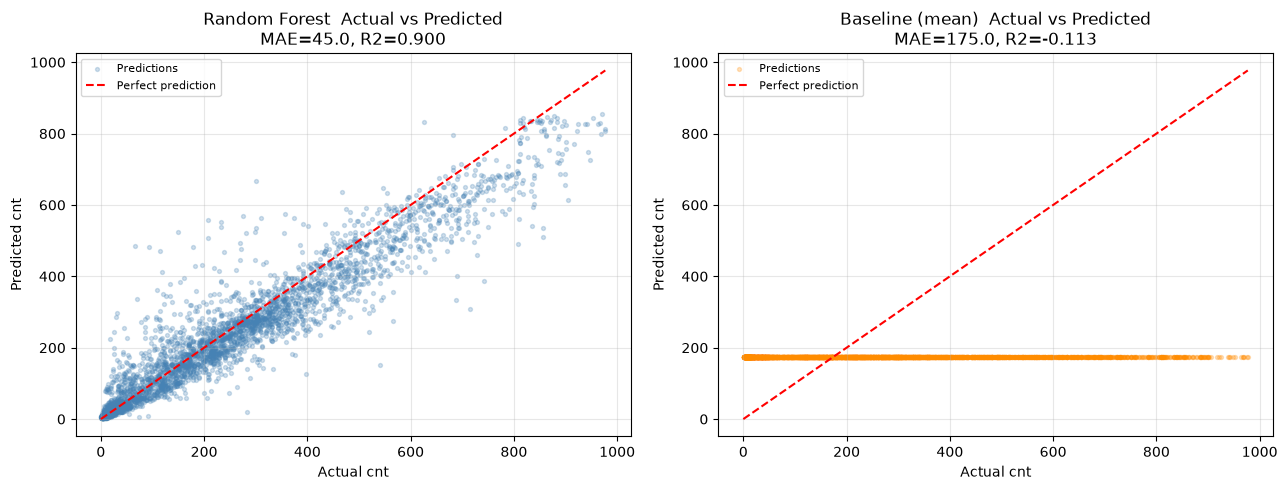

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Random Forest ---
ax = axes[0]
ax.scatter(y_test, y_pred_rf, alpha=0.25, s=8, color='steelblue', label='Predictions')
max_val = max(y_test.max(), y_pred_rf.max())
ax.plot([0, max_val], [0, max_val], 'r--', linewidth=1.5, label='Perfect prediction')
ax.set_xlabel('Actual cnt')
ax.set_ylabel('Predicted cnt')
ax.set_title(f'Random Forest  Actual vs Predicted\nMAE={mae_rf:.1f}, R2={r2_rf:.3f}')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# --- Baseline ---
ax = axes[1]
ax.scatter(y_test, y_pred_baseline, alpha=0.25, s=8, color='darkorange',
           label='Predictions')
ax.plot([0, max_val], [0, max_val], 'r--', linewidth=1.5, label='Perfect prediction')
ax.set_xlabel('Actual cnt')
ax.set_ylabel('Predicted cnt')
ax.set_title(f'Baseline (mean)  Actual vs Predicted\nMAE={mae_b:.1f}, R2={r2_b:.3f}')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Feature Importance (Random Forest)

Feature importance from a Random Forest reflects the **mean decrease in impurity**
averaged across all trees. It indicates which features the model relied on most.

**Important:** High importance is not evidence of causation. `hr` is important because
it strongly correlates with demand patterns — but whether the hour *causes* demand
changes requires a separate causal study design.

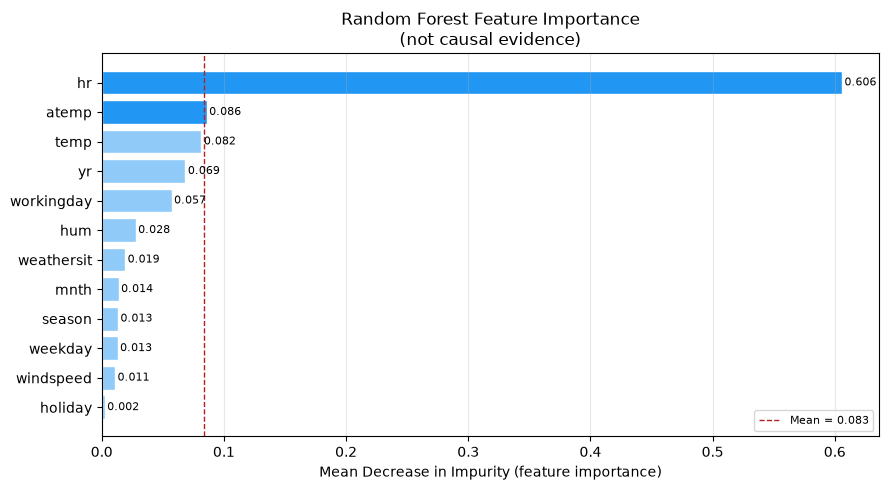

Feature importances (sorted):
hr            0.6059
atemp         0.0860
temp          0.0816
yr            0.0685
workingday    0.0572
hum           0.0278
weathersit    0.0192
mnth          0.0139
season        0.0133
weekday       0.0131
windspeed     0.0109
holiday       0.0025


In [18]:
importances = rf_pipeline.named_steps['rf'].feature_importances_
feat_imp = pd.Series(importances, index=FEATURE_COLS).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
mean_imp = feat_imp.mean()
colors = ['#2196F3' if v >= mean_imp else '#90CAF9' for v in feat_imp.values]
bars = ax.barh(
    feat_imp.index[::-1],
    feat_imp.values[::-1],
    color=colors[::-1],
    edgecolor='white'
)

for bar, val in zip(bars, feat_imp.values[::-1]):
    ax.text(bar.get_width() + 0.002,
            bar.get_y() + bar.get_height() / 2,
            f'{val:.3f}', va='center', fontsize=8)

ax.set_xlabel('Mean Decrease in Impurity (feature importance)')
ax.set_title('Random Forest Feature Importance\n(not causal evidence)')
ax.axvline(mean_imp, color='firebrick', linestyle='--',
           linewidth=1, label=f'Mean = {mean_imp:.3f}')
ax.legend(fontsize=8)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print('Feature importances (sorted):')
print(feat_imp.round(4).to_string())

### Residual Analysis

Residuals = actual − predicted. A well-fitting model should have residuals
centred at zero with roughly symmetric spread.

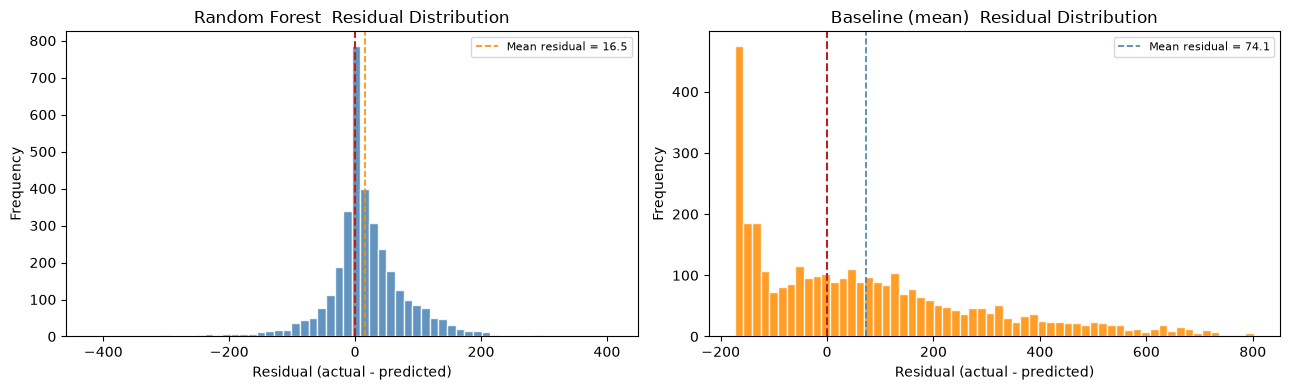

RF residuals     Mean: 16.46,  Std: 67.65
Baseline residuals  Mean: 74.12, Std: 220.48


In [19]:
residuals_rf = y_test.values - y_pred_rf
residuals_bl = y_test.values - y_pred_baseline

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# RF residuals
axes[0].hist(residuals_rf, bins=60, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(0, color='firebrick', linestyle='--', linewidth=1.5)
axes[0].axvline(residuals_rf.mean(), color='darkorange', linestyle='--',
                linewidth=1.2,
                label=f'Mean residual = {residuals_rf.mean():.1f}')
axes[0].set_xlabel('Residual (actual - predicted)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Random Forest  Residual Distribution')
axes[0].legend(fontsize=8)

# Baseline residuals
axes[1].hist(residuals_bl, bins=60, color='darkorange', edgecolor='white', alpha=0.85)
axes[1].axvline(0, color='firebrick', linestyle='--', linewidth=1.5)
axes[1].axvline(residuals_bl.mean(), color='steelblue', linestyle='--',
                linewidth=1.2,
                label=f'Mean residual = {residuals_bl.mean():.1f}')
axes[1].set_xlabel('Residual (actual - predicted)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Baseline (mean)  Residual Distribution')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print(f'RF residuals     Mean: {residuals_rf.mean():.2f},  Std: {residuals_rf.std():.2f}')
print(f'Baseline residuals  Mean: {residuals_bl.mean():.2f}, Std: {residuals_bl.std():.2f}')

---
## Section 7 — Key Findings and Conclusions

### 7.1 Demand Patterns (EDA findings)

**Hour-of-day** is the dominant cyclic driver of hourly demand:
- Evening commuter peak at **17:00: mean 461.5 rentals/hour**
- Morning commuter peak at **08:00: mean 359.0 rentals/hour**
- Overnight minimum at **04:00: mean 6.4 rentals/hour**

**Temperature** shows the strongest linear association with demand (`r = +0.405`).
Warm, comfortable conditions correlate with higher ridership.

**Weather** suppresses demand monotonically:
- Clear conditions: 204.9 rentals/hour
- Light rain or snow: 111.6 rentals/hour (−46% vs clear)
- Heavy rain / ice: 74.3 rentals/hour (−64% vs clear)

**Year-on-year growth:** Demand grew **63%** from 2011 (mean 143.8) to 2012 (mean 234.7),
suggesting programme expansion or increased adoption.

**Season:** Fall has the highest mean demand (236.0); Spring the lowest (111.1) —
a 2.1:1 ratio.

> All correlations are descriptive statistics for this dataset only.
> They do not establish causal mechanisms.

### 7.2 Model Performance

| Model | MAE | RMSE | R² |
|-------|-----|------|----|
| Baseline (DummyRegressor, mean) | 174.98 | 232.61 | −0.113 |
| Random Forest (100 trees, seed=42) | 45.02 | 69.62 | **0.900** |

The Random Forest achieves **R² = 0.90**, explaining 90% of the variance in
hourly demand on the held-out test set. It reduces MAE by **74.3%** relative
to the mean-prediction baseline.

Hour of day (`hr`), apparent temperature (`atemp`), and temperature (`temp`) are the top three
features by mean decrease in impurity.

### 7.3 Limitations

1. **Geography:** Data comes from Washington D.C. (2011–2012). Results may not
   generalise to other cities, climates, or time periods.
2. **`yr` as a predictor:** The model learns year-level growth trends. It cannot
   extrapolate to 2013 or beyond meaningfully.
3. **Weather category 4:** Only 3 observations exist in the dataset.
   Predictions under extreme conditions carry high uncertainty.
4. **No causal evidence:** Correlations and feature importances describe
   statistical patterns, not causal mechanisms.
5. **Chronological split:** The train/test boundary is a sharp date cut;
   real deployment would need ongoing retraining as conditions change.
6. **Non-negative predictions:** A Random Forest averages training targets (all ≥ 1),
   so it cannot predict below zero; negative outputs are a concern only for linear models.

### 7.4 Citation

> Fanaee-T, H., & Gama, J. (2013). Event labeling combining ensemble detectors and
> background knowledge. *Progress in Artificial Intelligence*, 2(2–3), 113–127.
> https://doi.org/10.1007/s13748-013-0040-3
>
> Dataset: UCI Machine Learning Repository — Bike Sharing Dataset (ID 275).
> https://archive.ics.uci.edu/dataset/275/bike-sharing-dataset

---
*Notebook produced as part of a multi-agent data science demonstration.*